# 01 - Dataset exploration (Person 1)
Partitions used: **train (80 trips)** for all fitting decisions (label audit, candidate radius/K); **student_test (10 trips)** only to report the same statistics.
The evaluator-test partition is never touched. Run from the repo root: `python -m src.data.eda_inventory` etc. (see `docs/P1_DATA_NOTES.md`); this notebook only reads their outputs.

In [1]:
import sys, os; os.chdir(os.path.abspath('..')) if os.path.basename(os.getcwd())=='notebooks' else None; sys.path.insert(0, '.')
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
inv = pd.read_csv('results/eda/trip_inventory.csv', dtype={'trip_id': str})

## 1. Inventory (partition = train / student_test)

In [2]:
inv.groupby('partition').agg(trips=('trip_id','count'), gps=('n_gps','sum'), gps_min=('n_gps','min'), gps_med=('n_gps','median'), gps_max=('n_gps','max'),
    nodes_med=('n_nodes','median'), arcs_med=('n_arcs','median'), route_arcs_med=('n_route_arcs','median'))

,trips,gps,gps_min,gps_med,gps_max,nodes_med,arcs_med,route_arcs_med
partition,,,,,,,,
student_test,10,19160,262,1420.0,3958,6596.5,13145.0,250.0
train,80,208417,361,1529.0,19313,9608.0,19526.5,280.0


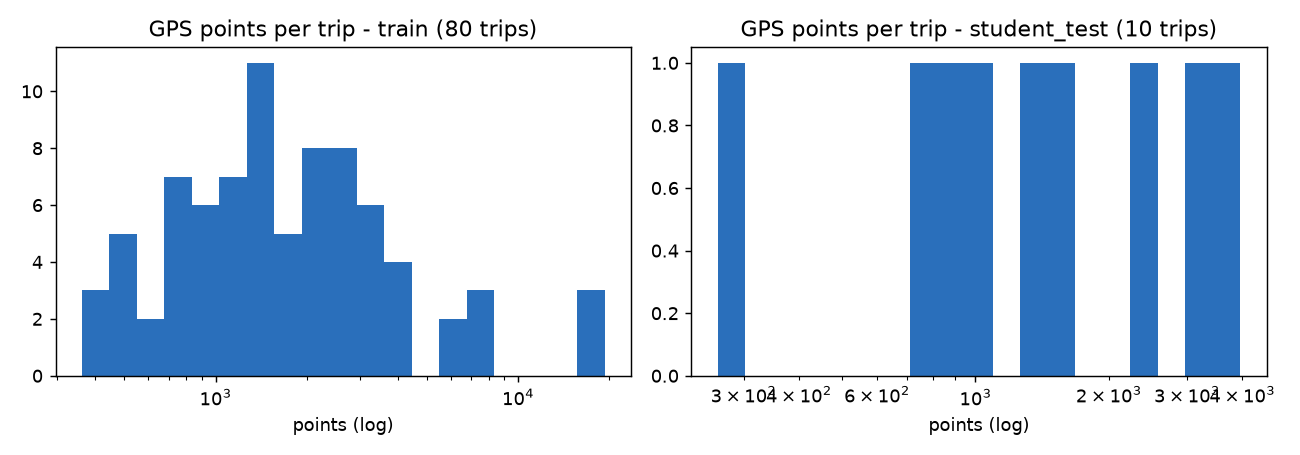

In [3]:
display(Image('results/eda/plots/01_points_per_trip.png'))

## 2. Data quality
* No NaN / duplicate rows; timestamps strictly increasing; every GPS fix lies inside its network's bounding box; no isolated nodes.
* **Trips are worldwide** (one city per trip) -> a per-trip local azimuthal-equidistant projection is used instead of a global UTM zone.

In [4]:
q = inv.groupby('partition').agg(nan=('gps_nan','sum'), dups=('gps_dup_rows','sum'), nonmono=('t_monotonic', lambda s: (~s).sum()),
    dt1_frac=('dt_eq1_frac','mean'), trips_gap_gt60s=('dt_max', lambda s: (s>60).sum()), trips_jump_gt100m=('n_jumps_gt100m', lambda s:(s>0).sum()),
    trips_zero_len_arcs=('zero_len_arcs', lambda s:(s>0).sum()), trips_multi_component=('weak_components', lambda s:(s>1).sum()),
    trips_broken_route=('route_connected_frac', lambda s:(s<1).sum()))
q

,nan,dups,nonmono,dt1_frac,trips_gap_gt60s,trips_jump_gt100m,trips_zero_len_arcs,trips_multi_component,trips_broken_route
partition,,,,,,,,,
student_test,0,0,0,0.981990,1,0,3,10,1
train,0,0,0,0.938296,22,23,29,79,10


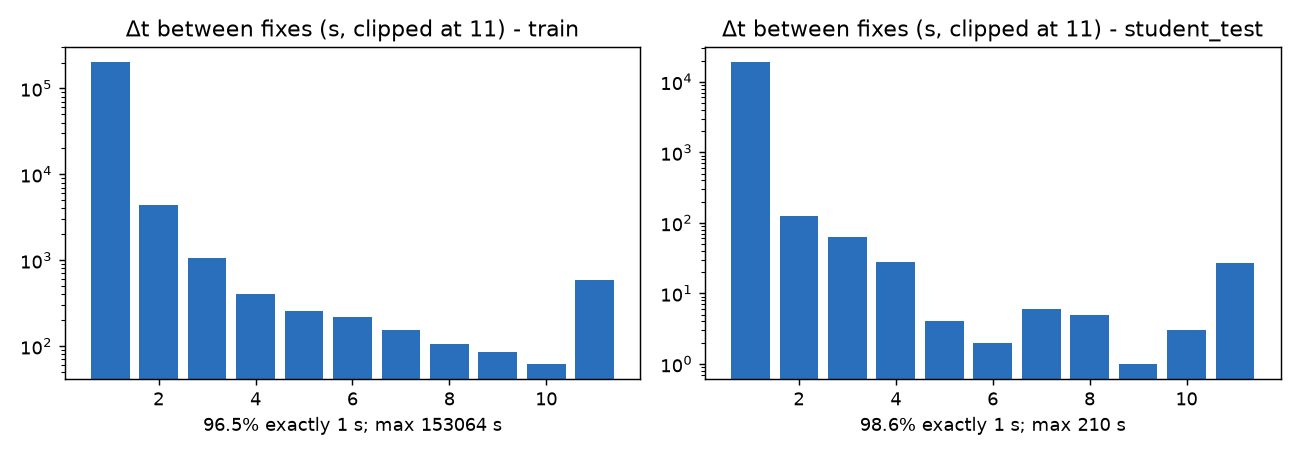

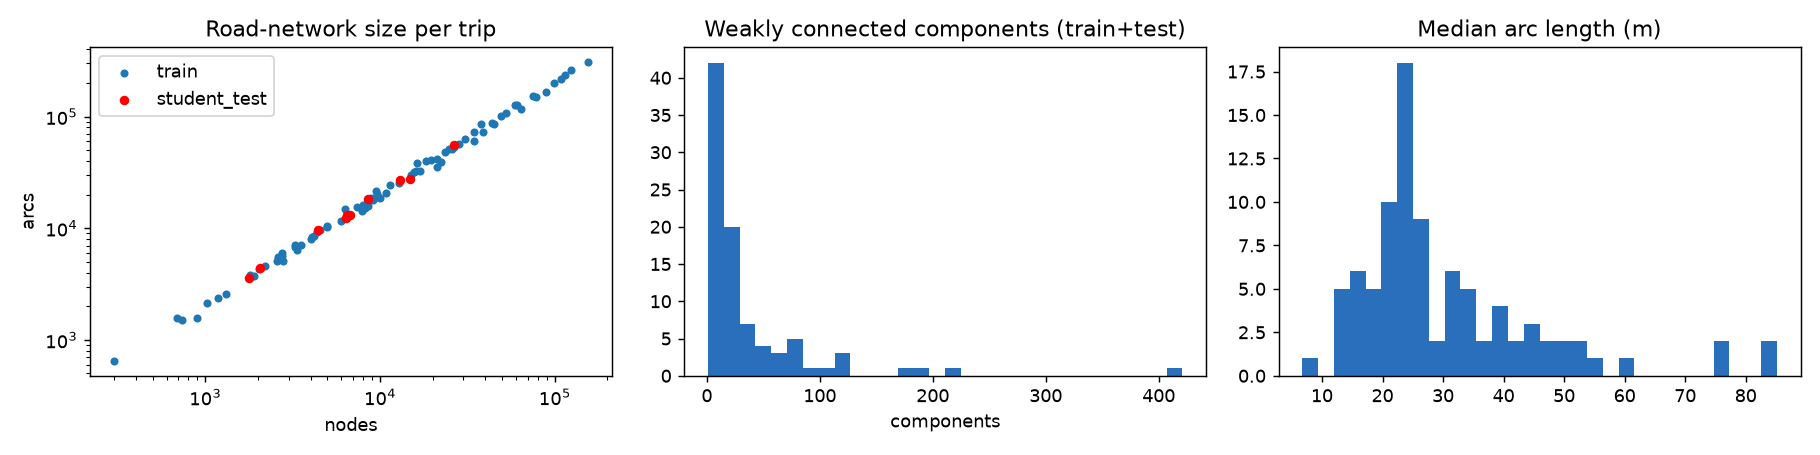

,trip_id,partition,n_gps,dt_max,n_gaps_gt5s,n_jumps_gt100m,step_max_m
72,00000090,train,536,153064.0,20,0,35.737488
61,00000078,train,2909,52810.0,124,79,215.749505
55,00000069,train,2067,2658.0,2,0,66.350580
16,00000021,train,15783,2161.0,2,0,45.863376
8,00000011,train,2828,909.0,1,0,50.396977
34,00000042,train,7739,670.0,45,0,58.241297


In [5]:
display(Image('results/eda/plots/02_dt_distribution.png')); display(Image('results/eda/plots/03_network_stats.png'))
inv.sort_values('dt_max', ascending=False)[['trip_id','partition','n_gps','dt_max','n_gaps_gt5s','n_jumps_gt100m','step_max_m']].head(6)

## 3. Reference route -> per-point labels
`.route` lists arcs only. Labels are derived with a monotone DP alignment (`src/data/p1_labels.py`). Validation: GPS-to-label distance and a visual check on hard trips.

In [6]:
la = pd.read_csv('results/eda/label_audit.csv', dtype={'trip_id': str})
display(la.groupby('partition')[['d_med','d_p90','d_p99','frac_gt100']].describe().T.round(2))
la[la.frac_gt100 > 0.1][['trip_id','partition','d_med','d_p90','frac_gt100']]

partition         student_test   train
d_med      count         10.00   80.00
           mean           5.09    8.16
           std            0.91   19.92
           min            4.18    3.45
           25%            4.43    4.29
           50%            4.75    4.64
           75%            5.77    5.56
           max            6.85  140.12
d_p90      count         10.00   80.00
           mean          13.28   18.13
           std            3.04   26.76
           min            9.86    8.70
           25%           10.99   10.72
           50%           12.54   11.84
           75%           14.84   14.67
           max           19.90  197.01
d_p99      count         10.00   80.00
           mean          25.32   46.88
           std            7.33   90.60
           min           15.96   12.47
           25%           19.53   18.23
           50%           25.05   20.60
           75%           30.72   34.15
           max           37.06  637.71
frac_gt100 count         10.00   80.00
           mean           0.00    0.02
           std            0.00    0.11
           min            0.00    0.00
           25%            0.00    0.00
           50%            0.00    0.00
           75%            0.00    0.00
           max            0.00    0.85

,trip_id,partition,d_med,d_p90,frac_gt100
26,00000033,train,122.421322,139.690351,0.509582
44,00000054,train,140.116231,197.014816,0.852017


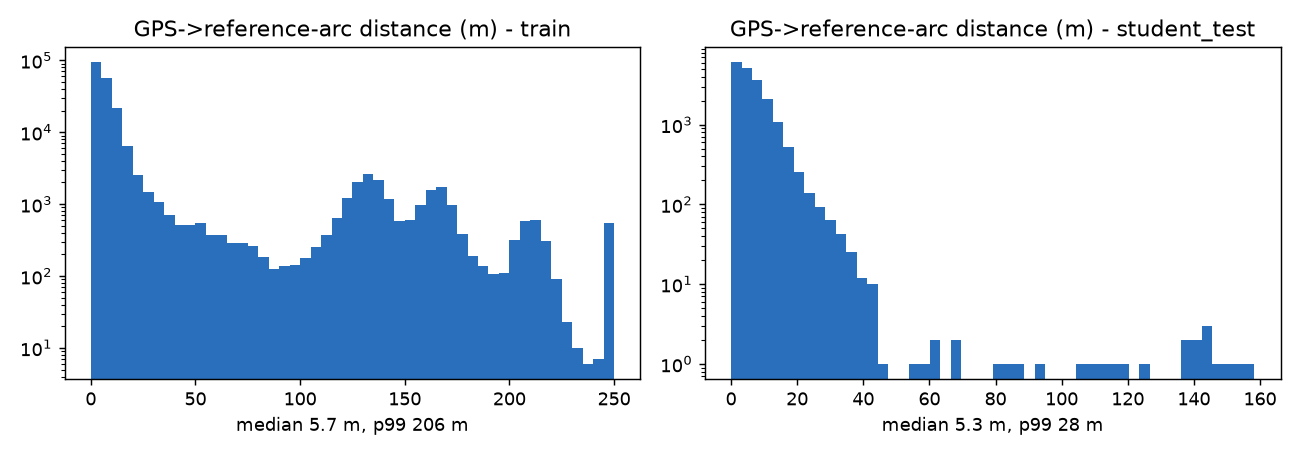

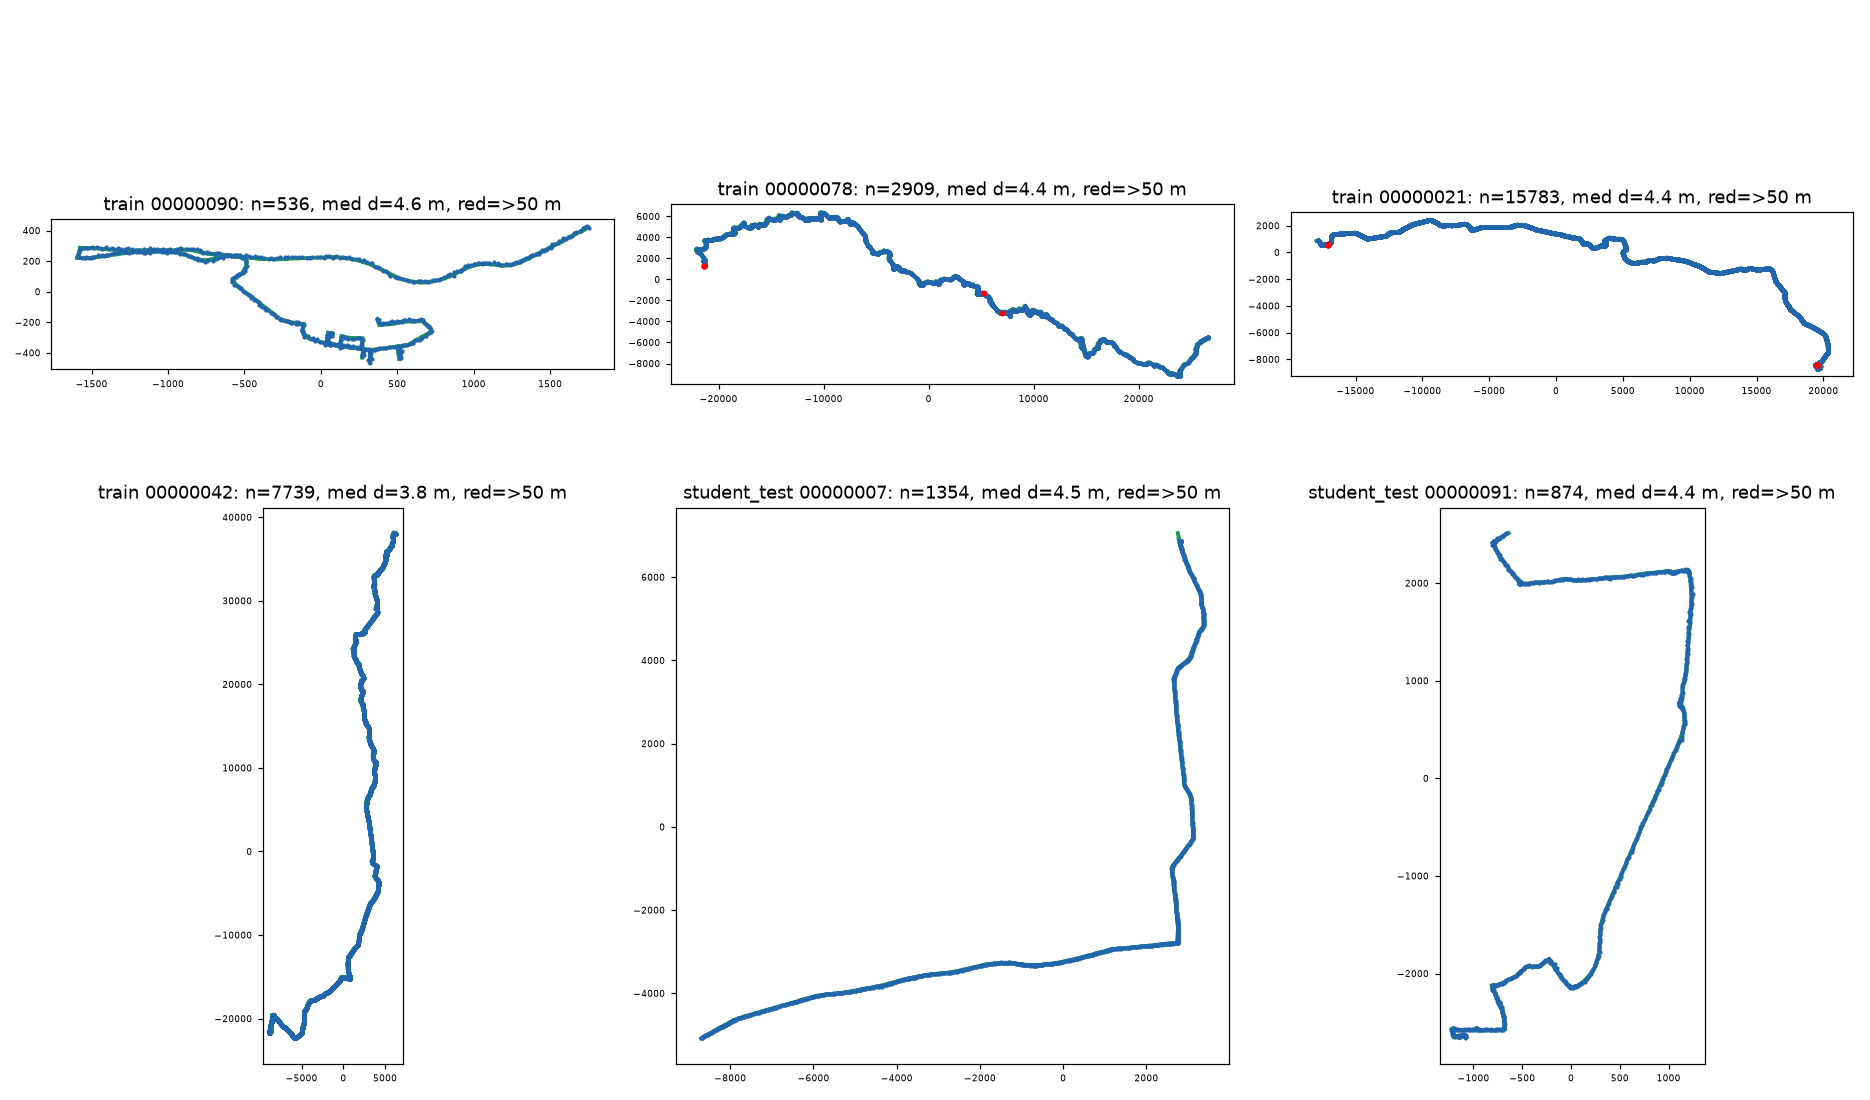

In [7]:
display(Image('results/eda/plots/04_label_distance.png')); display(Image('results/eda/plots/07_label_alignment_check.png'))

Trips **33 and 54** (train) are flagged: the GPS drifts ~130 m from the reference route for long stretches (offset ~0 at the start, ~130 m mid-trip - not a constant shift), so the true arc is outside any sensible candidate radius.
The reference route is therefore *reference* information, not verified truth. Recommendation: exclude/report separately.

## 4. Candidate generation (radius R, cap K chosen on train only)

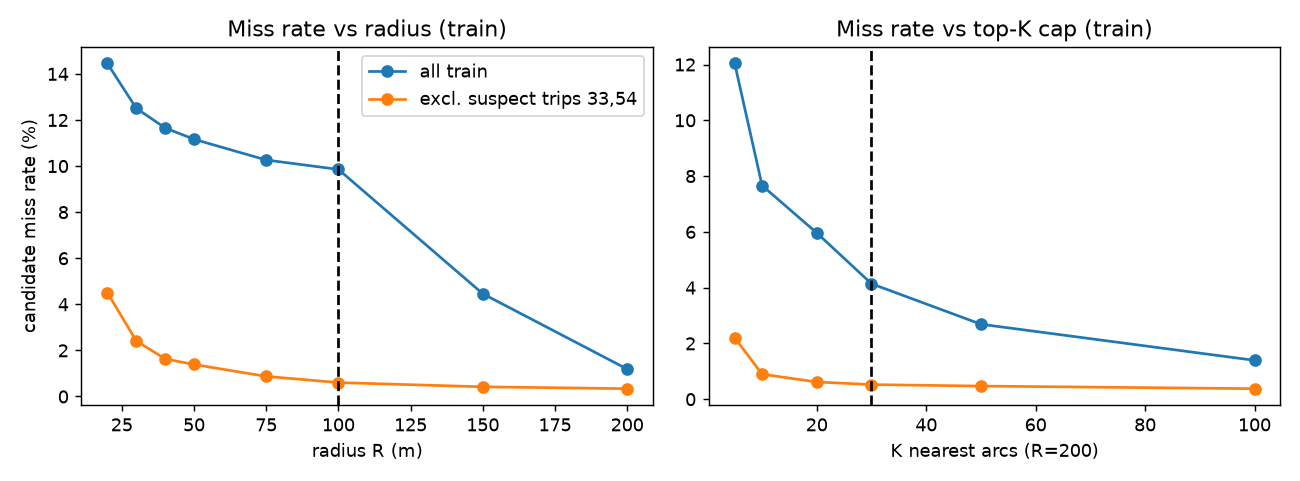

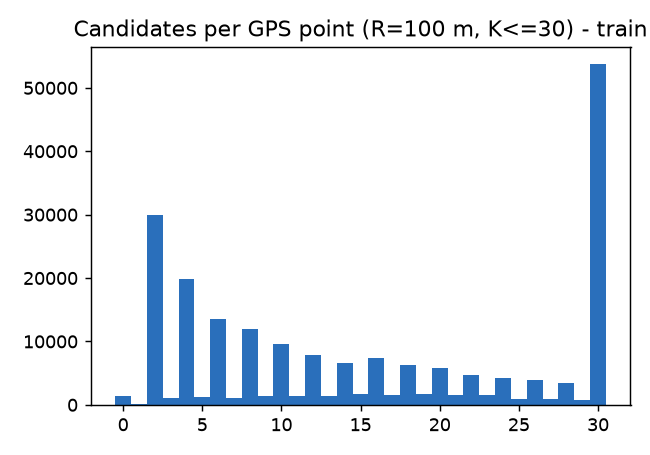

train: miss all=0.1016  clean trips=0.0065  cands/pt=15.6  at K cap=25.8%  no candidates=0.68%
student_test: miss all=0.0009  clean trips=0.0009  cands/pt=19.1  at K cap=41.6%  no candidates=0.00%


In [8]:
display(Image('results/eda/plots/05_candidate_miss_rate.png')); display(Image('results/eda/plots/06_candidates_per_point.png'))
pts = {p: pd.read_parquet(f'data/processed/{p}_points.parquet') for p in ['train','student_test']}
for p, d in pts.items():
    ok = d[~d.trip_label_suspect]
    print(f'{p}: miss all={1-d.label_in_candidates.mean():.4f}  clean trips={1-ok.label_in_candidates.mean():.4f}  cands/pt={d.n_candidates.mean():.1f}  at K cap={(d.n_candidates==30).mean():.1%}  no candidates={(d.n_candidates==0).mean():.2%}')

Chosen **R = 100 m, K = 30**: clean-trip miss rate ~0.65% (train) / 0.09% (student_test). R = 50 m doubles the miss rate; R = 150 m adds ~2x candidates for ~0.2 pp. ~26% of train points hit the K cap (dense urban networks), so P2 should include `rank` / distance-gap features.

## 5. Interactive map
Open `results/maps/eda_train_00000001.html` (GPS fixes, nearby network, reference route, candidates of one point) and `results/maps/eda_train_00000033_drift.html` (GPS drift).

In [9]:
import folium
from src.data.p1_loader import load_trip
from src.viz.p1_folium_map import make_map
make_map(load_trip('00000001','train'), point_slice=slice(0,150), show_candidates_for=75)

## 6. Hand-off
See `docs/P1_DATA_NOTES.md` for the table schemas: `data/processed/{train,student_test}_{points,candidates}.parquet`.